# 3D Printer
The printer head is moved by two motors (left and right). Each motor has a mechanical part (angle, speed) and an electrical part (current).

States:
- $x_1$: angle of left motor, $x_2$: speed of left motor, $x_3$: current of left motor
- $x_4$: angle of right motor, $x_5$: speed of right motor, $x_6$: current of right motor

$$\begin{bmatrix} \dot{x}_1 \\ \dot{x}_2 \\ \dot{x}_3 \\ \dot{x}_4 \\ \dot{x}_5 \\ \dot{x}_6 \end{bmatrix} = \begin{bmatrix} x_2 \\ \frac{K_m x_3 - \left[ \frac{r_m^2}{4}(\mu_{l,x} + \mu_{l,y}) + \mu_r \right] x_2 - \left[ \frac{r_m^2}{4}(\mu_{l,x} - \mu_{l,y}) \right] x_5}{\frac{1}{2}m r_m^2 + J_m} \\ \frac{1}{L_m} (u_{m,l} - R_m x_3 - K_m x_2) \\ x_5 \\ \frac{K_m x_6 - \left[ \frac{r_m^2}{4}(\mu_{l,x} - \mu_{l,y}) \right] x_2 - \left[ \frac{r_m^2}{4}(\mu_{l,x} + \mu_{l,y}) + \mu_r \right] x_5}{\frac{1}{2}m r_m^2 + J_m} \\ \frac{1}{L_m} (u_{m,r} - R_m x_6 - K_m x_5) \end{bmatrix}$$

In [23]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from math import pi

## Parameters

In [24]:
###DONT USE THESE PARAMETERS IN THE SIMULATION, THEY ARE JUST FOR REFERENCE###



K_m  = 0.07    # motor constant (Nm/A)
r_m  = 0.011   # motor radius (m)
m    = 0.06    # tool head mass (kg)
J_m  = 8e-6    # motor inertia (kg m^2)
mu_lx = 0.002  # bearing friction linear x-direction (Ns/m)
mu_ly = 0.001  # bearing friction linear y-direction (Ns/m)
mu_r = 0.003   # bearing friction rolling (Ns/m)
L_m  = 0.01    # motor inductance (H)
R_m  = 90.0    # motor resistance (Ohm)

u_ml = 12.0    # voltage left motor (V) - not given, chosen
u_mr = 6.0     # voltage right motor (V) - not given, chosen


a = r_m**2 / 4 * (mu_lx + mu_ly) + mu_r
b = r_m**2 / 4 * (mu_lx - mu_ly)
J = 0.5 * m * r_m**2 + J_m

## System equations

In [25]:
def f(t, x):
    x1 = x[0]
    x2 = x[1]
    x3 = x[2]
    x4 = x[3]
    x5 = x[4]
    x6 = x[5]


    dx1 = x2
    dx2 = (K_m * x3 - a * x2 - b * x5) / J
    dx3 = (u_ml - R_m * x3 - K_m * x2) / L_m
    dx4 = x5
    dx5 = (K_m * x6 - b * x2 - a * x5) / J
    dx6 = (u_mr - R_m * x6 - K_m * x5) / L_m

    return [dx1, dx2, dx3, dx4, dx5, dx6]

## Simulate

In [26]:
x0 = [0, 0, 0, 0, 0, 0]
t_span = (0, 1)
t_eval = np.linspace(0, 1, 1000)

sol = solve_ivp(f, t_span, x0, t_eval=t_eval)


t = sol.t
x = sol.y

## Plot

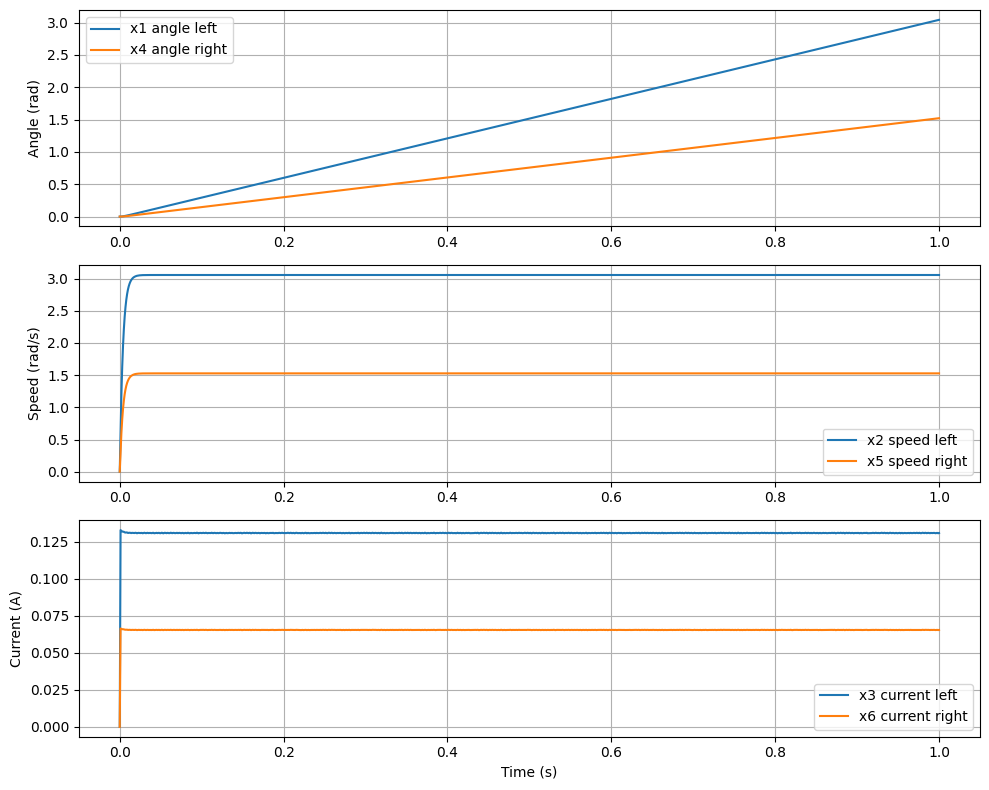

In [27]:
plt.figure(figsize=(10, 8))

plt.subplot(3, 1, 1)
plt.plot(t, x[0], label='x1 angle left')
plt.plot(t, x[3], label='x4 angle right')
plt.ylabel('Angle (rad)')
plt.legend()
plt.grid()

plt.subplot(3, 1, 2)
plt.plot(t, x[1], label='x2 speed left')
plt.plot(t, x[4], label='x5 speed right')
plt.ylabel('Speed (rad/s)')
plt.legend()
plt.grid()

plt.subplot(3, 1, 3)
plt.plot(t, x[2], label='x3 current left')
plt.plot(t, x[5], label='x6 current right')
plt.ylabel('Current (A)')
plt.xlabel('Time (s)')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

## Tool head trajectory
$$x = \frac{r_m}{2}(\theta_l + \theta_r), \quad y = \frac{r_m}{2}(\theta_l - \theta_r)$$
$$\dot x = \frac{r_m}{2}(\dot\theta_l + \dot\theta_r), \quad \dot y = \frac{r_m}{2}(\dot\theta_l - \dot\theta_r)$$

In [28]:
theta_l = x[0]
theta_l_dot = x[1]
theta_r = x[3]
theta_r_dot = x[4]

pos_x = r_m * (theta_l + theta_r) / 2
pos_y = r_m * (theta_l - theta_r) / 2
vel_x = r_m * (theta_l_dot + theta_r_dot) / 2
vel_y = r_m * (theta_l_dot - theta_r_dot) / 2

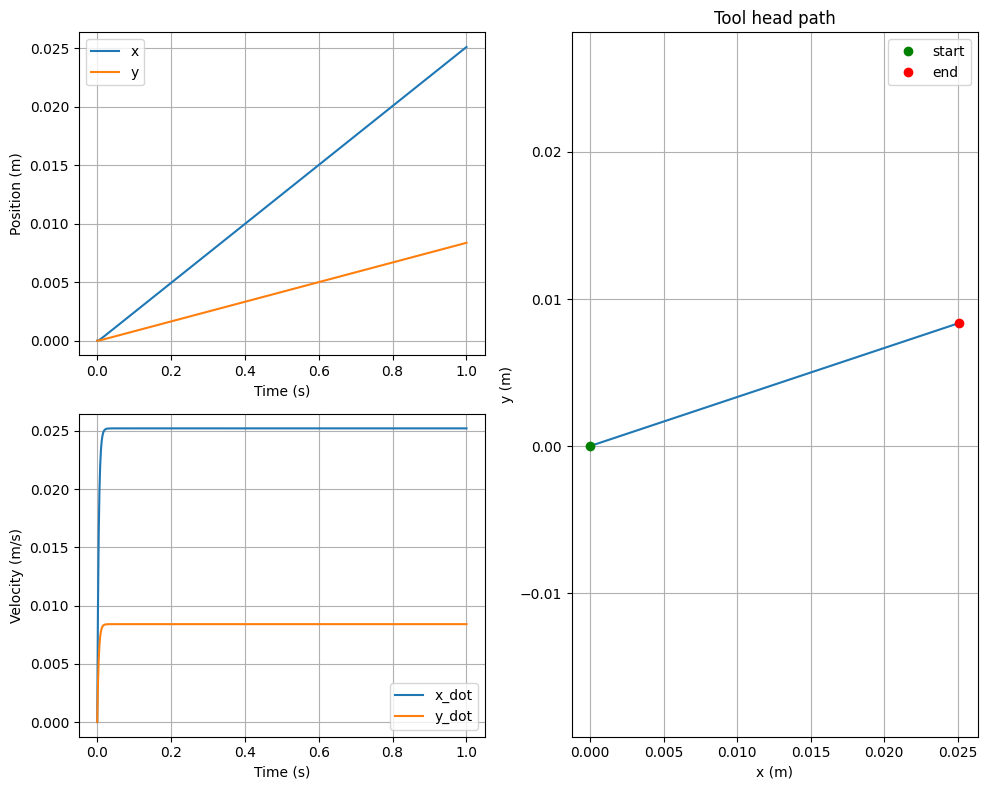

In [29]:
plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.plot(t, pos_x, label='x')
plt.plot(t, pos_y, label='y')
plt.ylabel('Position (m)')
plt.xlabel('Time (s)')
plt.legend()
plt.grid()

plt.subplot(2, 2, 3)
plt.plot(t, vel_x, label='x_dot')
plt.plot(t, vel_y, label='y_dot')
plt.ylabel('Velocity (m/s)')
plt.xlabel('Time (s)')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(pos_x, pos_y)
plt.plot(pos_x[0], pos_y[0], 'go', label='start')
plt.plot(pos_x[-1], pos_y[-1], 'ro', label='end')
plt.xlabel('x (m)')
plt.ylabel('y (m)')
plt.title('Tool head path')
plt.axis('equal')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

## Q1.3 Decoupled x and y dynamics
New inputs and currents (sum and difference of left and right):
$$i_x = \tfrac12(i_l+i_r),\quad i_y = \tfrac12(i_l-i_r),\qquad u_x = \tfrac12(u_l+u_r),\quad u_y = \tfrac12(u_l-u_r)$$

Adding and subtracting the motor equations removes the coupling. With $\boldsymbol x_x = [x,\ \dot x,\ i_x]^\top$:
$$\dot{\boldsymbol x}_x = \begin{bmatrix} \dot x \\ \dfrac{K_m r_m i_x - \left(\frac{r_m^2}{2}\mu_{l,x}+\mu_r\right)\dot x}{\frac12 m r_m^2 + J_m} \\ \dfrac{1}{L_m}\left(u_x - R_m i_x - \frac{K_m}{r_m}\dot x\right)\end{bmatrix}$$

The y-system is the same with $x \to y$, $\mu_{l,x} \to \mu_{l,y}$ and $u_y$. Back to motor voltages: $u_l = u_x + u_y$, $u_r = u_x - u_y$.

In [30]:
u_x = (u_ml + u_mr) / 2
u_y = (u_ml - u_mr) / 2

def f_x(t, s):
    pos = s[0]
    vel = s[1]
    cur = s[2]

    J = 0.5 * m * r_m**2 + J_m
    c = r_m**2 / 2 * mu_lx + mu_r

    dpos = vel
    dvel = (K_m * r_m * cur - c * vel) / J
    dcur = (u_x - R_m * cur - K_m / r_m * vel) / L_m

    return [dpos, dvel, dcur]


def f_y(t, s):
    pos = s[0]
    vel = s[1]
    cur = s[2]

    J = 0.5 * m * r_m**2 + J_m
    c = r_m**2 / 2 * mu_ly + mu_r

    dpos = vel
    dvel = (K_m * r_m * cur - c * vel) / J
    dcur = (u_y - R_m * cur - K_m / r_m * vel) / L_m

    return [dpos, dvel, dcur]

In [31]:
s0 = [0, 0, 0]

sol_x = solve_ivp(f_x, t_span, s0, t_eval=t_eval)
sol_y = solve_ivp(f_y, t_span, s0, t_eval=t_eval)

dec_x = sol_x.y[0]
dec_y = sol_y.y[0]

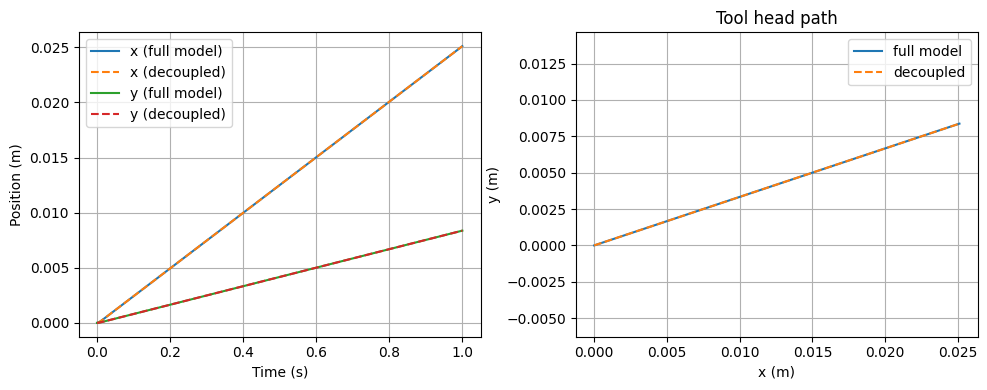

max error x: 2.6749671575010403e-10
max error y: 9.682682433620471e-11


In [32]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(t, pos_x, label='x (full model)')
plt.plot(t, dec_x, '--', label='x (decoupled)')
plt.plot(t, pos_y, label='y (full model)')
plt.plot(t, dec_y, '--', label='y (decoupled)')
plt.xlabel('Time (s)')
plt.ylabel('Position (m)')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(pos_x, pos_y, label='full model')
plt.plot(dec_x, dec_y, '--', label='decoupled')
plt.xlabel('x (m)')
plt.ylabel('y (m)')
plt.title('Tool head path')
plt.axis('equal')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

print('max error x:', np.max(np.abs(pos_x - dec_x)))
print('max error y:', np.max(np.abs(pos_y - dec_y)))

In [33]:
from scipy.interpolate import make_interp_spline

def u_ref_from_target_sp(x, y, speed, dt=1e-3):
    """Feedforward motor voltages to draw the path through the points (x, y) [m]
    with the nozzle moving at `speed` [m/s]. The result is sampled every dt [s].

    Returns u_ref (2, N), ref_state (6, N), t (N,) and derivs (2, 4, N), where
    derivs[0] = [x, x_dot, x_dot_dot, x_dot_dot_dot] and derivs[1] the same for y.
    """
    x = np.asarray(x, float)
    y = np.asarray(y, float)

    # time at each point from the path length at constant speed; drop repeated points
    s = np.concatenate([[0], np.cumsum(np.hypot(np.diff(x), np.diff(y)))])
    s, iu = np.unique(s, return_index=True)
    knots = s / speed

    # quintic spline through the points, differentiated three times
    spl = make_interp_spline(knots, np.array([x[iu], y[iu]]).T, k=5)
    t = np.arange(0, knots[-1], dt)
    derivs = np.array([spl.derivative(k)(t).T if k else spl(t).T for k in range(4)])
    (x, y), (x_dot, y_dot), (x_dot_dot, y_dot_dot), (x_dot_dot_dot, y_dot_dot_dot) = derivs

    theta_l_ref = (x+y)/r_m
    theta_r_ref = (x-y)/r_m

    theta_l_dot_ref = (x_dot+y_dot)/r_m
    theta_r_dot_ref = (x_dot-y_dot)/r_m

    theta_l_dot_dot_ref = (x_dot_dot+y_dot_dot)/r_m
    theta_r_dot_dot_ref = (x_dot_dot-y_dot_dot)/r_m

    theta_l_dot_dot_dot_ref = (x_dot_dot_dot+y_dot_dot_dot)/r_m
    theta_r_dot_dot_dot_ref = (x_dot_dot_dot-y_dot_dot_dot)/r_m

    i_l = (J*theta_l_dot_dot_ref + a*theta_l_dot_ref + b*theta_r_dot_ref)/K_m
    i_r = (J*theta_r_dot_dot_ref + b*theta_l_dot_ref + a*theta_r_dot_ref)/K_m

    i_l_dot = (J*theta_l_dot_dot_dot_ref + a*theta_l_dot_dot_ref + b*theta_r_dot_dot_ref)/K_m
    i_r_dot = (J*theta_r_dot_dot_dot_ref + b*theta_l_dot_dot_ref + a*theta_r_dot_dot_ref)/K_m

    # dx3 = (u_ml - R_m * x3 - K_m * x2) / L_m  ->  u = L_m * i_dot + R_m * i + K_m * theta_dot
    u_l = L_m*i_l_dot + R_m*i_l + K_m*theta_l_dot_ref
    u_r = L_m*i_r_dot + R_m*i_r + K_m*theta_r_dot_ref

    u_ref = np.array([u_l, u_r])

    # state order matches f_ref: [theta_l, theta_l_dot, i_l, theta_r, theta_r_dot, i_r], shape (6, N)
    ref_state = np.array([theta_l_ref, theta_l_dot_ref, i_l, theta_r_ref, theta_r_dot_ref, i_r])

    return u_ref, ref_state, t, derivs


In [34]:
T = 1
W = 2*pi/T

x_c = 20.0
y_c = 20.0
A = 2
B = 1
t = np.linspace(0,T,1000)

x = x_c + A*np.cos(W*t)
y = y_c + B*np.sin(W*t)

u_ref, ref_state, t, derivs = u_ref_from_target_sp(x, y, speed=10, dt=T/1000)
x, y = derivs[0]
T = t[-1]


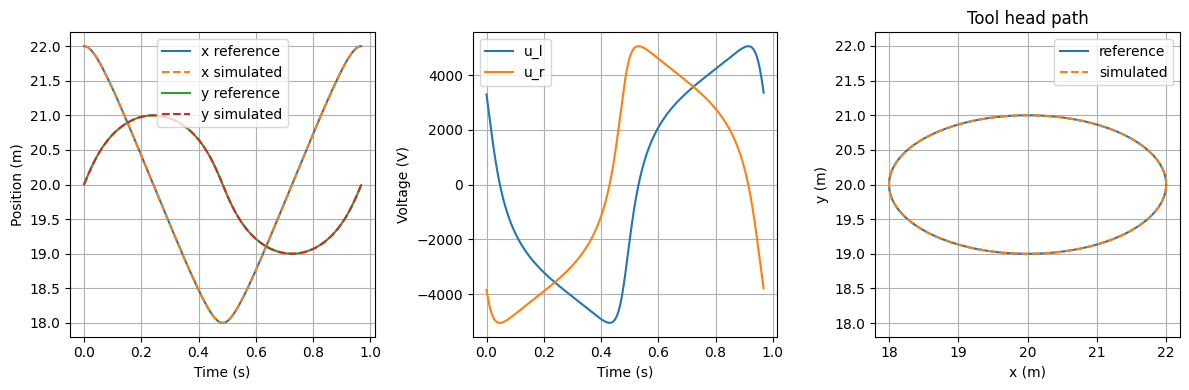

In [35]:
def f_ref(t_now, s):
    u_l_now = np.interp(t_now, t, u_ref[0])
    u_r_now = np.interp(t_now, t, u_ref[1])

    x1 = s[0]
    x2 = s[1]
    x3 = s[2]
    x4 = s[3]
    x5 = s[4]
    x6 = s[5]

    dx1 = x2
    dx2 = (K_m * x3 - a * x2 - b * x5) / J
    dx3 = (u_l_now - R_m * x3 - K_m * x2) / L_m
    dx4 = x5
    dx5 = (K_m * x6 - b * x2 - a * x5) / J
    dx6 = (u_r_now - R_m * x6 - K_m * x5) / L_m

    return [dx1, dx2, dx3, dx4, dx5, dx6]

s0_ref = ref_state[:, 0]   # initial state on the reference trajectory

sol_ref = solve_ivp(f_ref, (0, T), s0_ref, t_eval=t)

t_sim = sol_ref.t
theta_l_sim = sol_ref.y[0]
theta_r_sim = sol_ref.y[3]

x_sim = r_m * (theta_l_sim + theta_r_sim) / 2
y_sim = r_m * (theta_l_sim - theta_r_sim) / 2


plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.plot(t, x, label='x reference')
plt.plot(t_sim, x_sim, '--', label='x simulated')
plt.plot(t, y, label='y reference')
plt.plot(t_sim, y_sim, '--', label='y simulated')
plt.xlabel('Time (s)')
plt.ylabel('Position (m)')
plt.legend()
plt.grid()

plt.subplot(1, 3, 2)
plt.plot(t, u_ref[0], label='u_l')
plt.plot(t, u_ref[1], label='u_r')
plt.xlabel('Time (s)')
plt.ylabel('Voltage (V)')
plt.legend()
plt.grid()

plt.subplot(1, 3, 3)
plt.plot(x, y, label='reference')
plt.plot(x_sim, y_sim, '--', label='simulated')
plt.xlabel('x (m)')
plt.ylabel('y (m)')
plt.title('Tool head path')
plt.axis('equal')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

## TU Delft logo
Extract the outline of the logo, fit a quintic interpolating spline through it, differentiate it three times ($\dot x, \ddot x, \dddot x$, same for $y$) and feed the result to `u_ref_from_target_sp`.

number of contours: 10


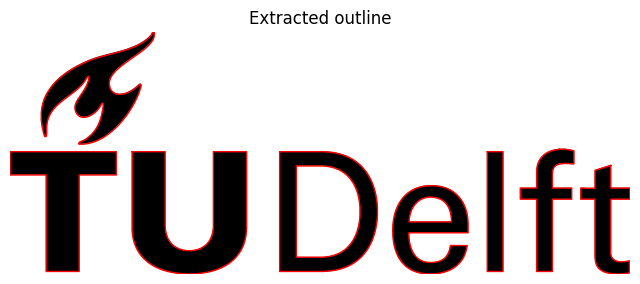

In [36]:
import cv2
from scipy.interpolate import make_interp_spline

# composite on white background (png has alpha), then binarise
img = cv2.imread('images/tudelft.png', cv2.IMREAD_UNCHANGED).astype(float)
if img.shape[2] == 4:
    alpha = img[:, :, 3:] / 255
    img = img[:, :, :3] * alpha + 255 * (1 - alpha)
gray = img.mean(axis=2)
mask = (gray < 250).astype(np.uint8)

# outer contours and holes (D, e, l, ... have holes)
contours, _ = cv2.findContours(mask, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_NONE)
print('number of contours:', len(contours))

plt.figure(figsize=(8, 4))
plt.imshow(mask, cmap='gray_r')
for c in contours:
    plt.plot(c[:, 0, 0], c[:, 0, 1], 'r', lw=1)
plt.title('Extracted outline')
plt.axis('off')
plt.show()

In [37]:
num_points = 120    # control points per contour

ctrl = []
for c in contours:
    px = c[:, 0, 0].astype(float)
    py = -c[:, 0, 1].astype(float)
    idx = np.unique(np.round(np.linspace(0, len(px) - 1, num_points)).astype(int))
    ctrl.append(np.array([px[idx], py[idx]]))
ctrl = np.hstack(ctrl)

print_area = 0.29
draw_size = 0.20
margin = (print_area - draw_size) / 2
px_to_m = draw_size / max(mask.shape)

ctrl = ctrl - ctrl.min(axis=1, keepdims=True)
ctrl = margin + px_to_m * ctrl

# arc length parametrisation, resampled to uniform spacing
seg = np.linalg.norm(np.diff(ctrl, axis=1), axis=0)
s = np.concatenate([[0], np.cumsum(seg)])
s, iu = np.unique(s, return_index=True)
s_q = np.linspace(0, s[-1], int(np.ceil(s[-1] / np.median(np.diff(s)))) + 1)
pts = np.array([np.interp(s_q, s, ctrl[0, iu]), np.interp(s_q, s, ctrl[1, iu])])

In [54]:
v_avg = 0.01                      # nozzle speed (m/s)

u_ref_tud, ref_state_tud, t_tud, derivs_tud = u_ref_from_target_sp(pts[0], pts[1], speed=0.5)
T_tud = t_tud[-1]

x_tud, y_tud = derivs_tud[0]
xd_tud, yd_tud = derivs_tud[1]
xdd_tud, ydd_tud = derivs_tud[2]
xddd_tud, yddd_tud = derivs_tud[3]
print(f'T = {T_tud:.1f} s, {len(t_tud)} samples')

T = 3.6 s, 3576 samples


In [55]:
def f_ref_tud(t_now, s):
    u_l_now = np.interp(t_now, t_tud, u_ref_tud[0])
    u_r_now = np.interp(t_now, t_tud, u_ref_tud[1])
    return [s[1],
            (K_m * s[2] - a * s[1] - b * s[4]) / J,
            (u_l_now - R_m * s[2] - K_m * s[1]) / L_m,
            s[4],
            (K_m * s[5] - b * s[1] - a * s[4]) / J,
            (u_r_now - R_m * s[5] - K_m * s[4]) / L_m]

# electrical dynamics are fast (L/R ~ 1e-4 s), so use a stiff solver
sol_tud = solve_ivp(f_ref_tud, (0, T_tud), ref_state_tud[:, 0], t_eval=t_tud,
                    method='LSODA', rtol=1e-8, atol=1e-10)

x_sim_tud = r_m * (sol_tud.y[0] + sol_tud.y[3]) / 2
y_sim_tud = r_m * (sol_tud.y[0] - sol_tud.y[3]) / 2

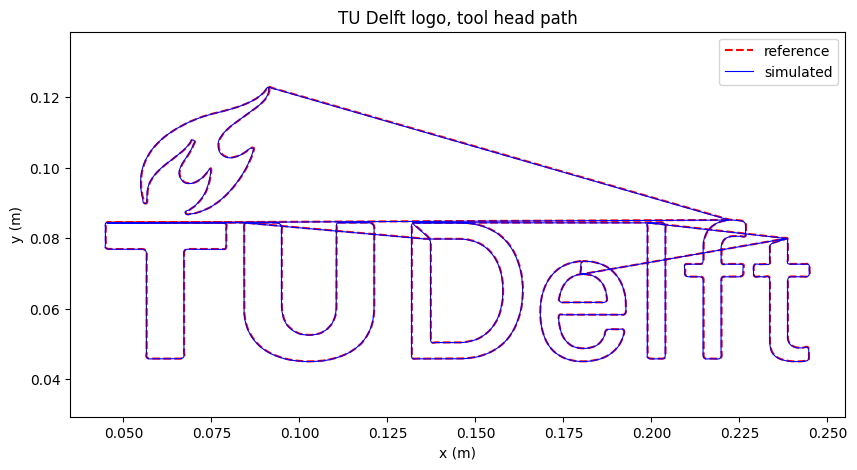

max position error (mm): 0.22031138688050786


In [56]:
plt.figure(figsize=(10, 5))
plt.plot(x_tud, y_tud, 'r--', label='reference')
plt.plot(x_sim_tud, y_sim_tud, 'b-', lw=0.8, label='simulated')
plt.xlabel('x (m)')
plt.ylabel('y (m)')
plt.title('TU Delft logo, tool head path')
plt.axis('equal')
plt.legend()
plt.grid# The constants were blindly generated from my notes so I can run the simulation, they need to be checked and probably changed (density seems a bit too high for plastic :) 
()
plt.show()

print('max position error (mm):', 1e3 * np.max(np.hypot(x_sim_tud - x_tud, y_sim_tud - y_tud)))

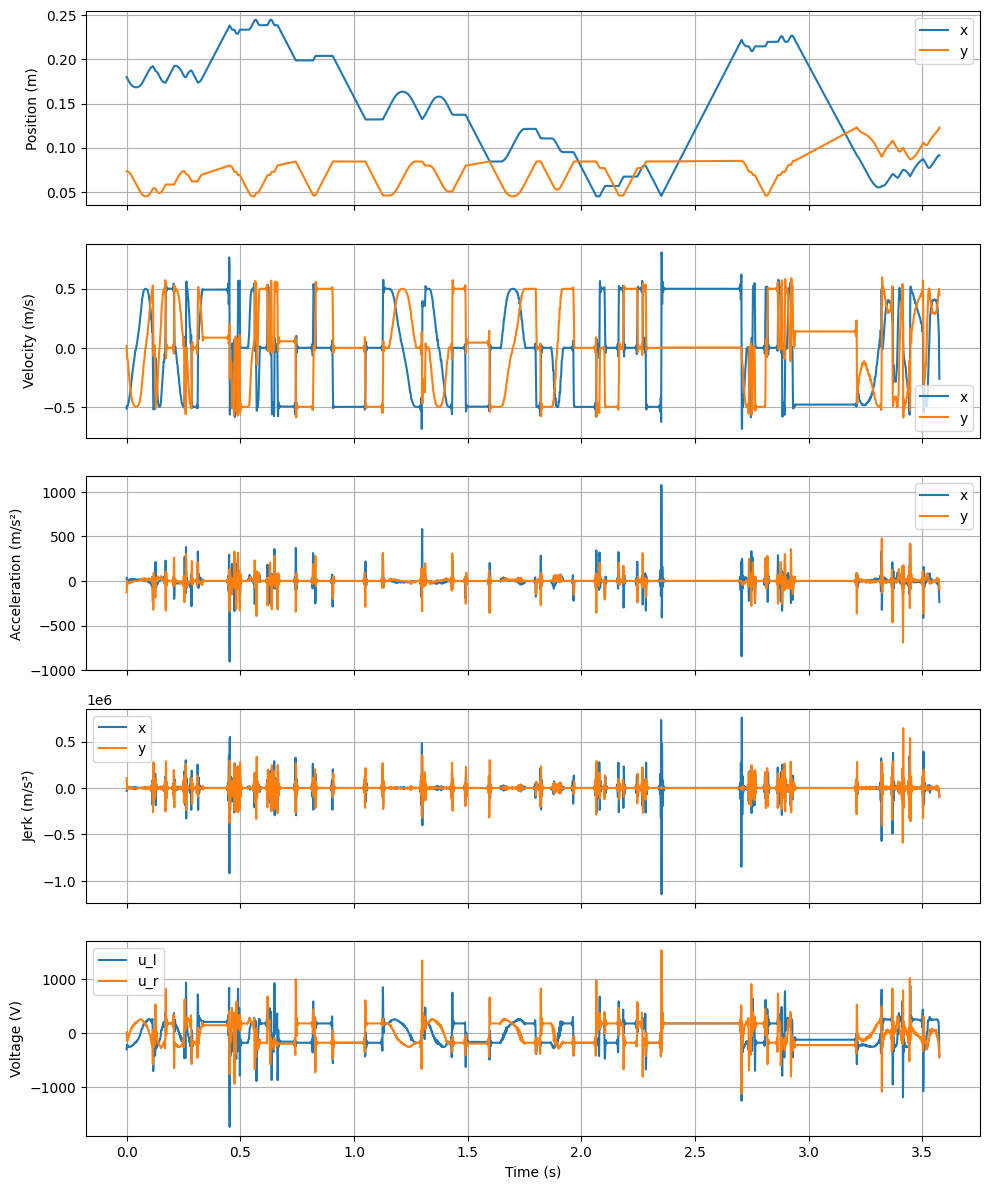

In [57]:
fig, ax = plt.subplots(5, 1, figsize=(10, 12), sharex=True)
for axi, (xv, yv, lab) in zip(ax, [(x_tud, y_tud, 'Position (m)'),
                                   (xd_tud, yd_tud, 'Velocity (m/s)'),
                                   (xdd_tud, ydd_tud, 'Acceleration (m/s²)'),
                                   (xddd_tud, yddd_tud, 'Jerk (m/s³)')]):
    axi.plot(t_tud, xv, label='x')
    axi.plot(t_tud, yv, label='y')
    axi.set_ylabel(lab)
    axi.legend()
    axi.grid()
ax[4].plot(t_tud, u_ref_tud[0], label='u_l')
ax[4].plot(t_tud, u_ref_tud[1], label='u_r')
ax[4].set_ylabel('Voltage (V)')
ax[4].set_xlabel('Time (s)')
ax[4].legend()
ax[4].grid()
plt.tight_layout()
plt.show()